# Task 5: SQL-Based Analysis of Product Sales (Chinook)

**Goal:** Answer three business questions with SQL:
1. What are the top-selling products?
2. What is revenue per region?
3. How does monthly performance change over time?

**Tools:** SQLite + pandas + seaborn

In [1]:
import os, sqlite3, urllib.request
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

DB = "Chinook_Sqlite.sqlite"
URL = "https://raw.githubusercontent.com/lerocha/chinook-database/master/ChinookDatabase/DataSources/Chinook_Sqlite.sqlite"
if not os.path.exists(DB):
    urllib.request.urlretrieve(URL, DB)

conn = sqlite3.connect(DB)

def run(sql):
    return pd.read_sql_query(sql, conn)

print("SQLite", sqlite3.sqlite_version)

SQLite 3.45.1


In [2]:
q1 = """
SELECT
    ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS total_revenue,
    COUNT(DISTINCT il.InvoiceId)              AS invoices,
    COUNT(DISTINCT i.CustomerId)              AS customers,
    ROUND(SUM(il.UnitPrice * il.Quantity) / COUNT(DISTINCT il.InvoiceId), 2) AS avg_order_value
FROM InvoiceLine il
JOIN Invoice i ON i.InvoiceId = il.InvoiceId
"""
q1_df = run(q1); display(q1_df)

mismatch_df = run("""
SELECT COUNT(*) AS mismatches
FROM Invoice i
JOIN (SELECT InvoiceId, SUM(UnitPrice * Quantity) AS line_total
      FROM InvoiceLine GROUP BY InvoiceId) l ON l.InvoiceId = i.InvoiceId
WHERE ROUND(l.line_total - i.Total, 2) <> 0
""")
display(mismatch_df)

,total_revenue,invoices,customers,avg_order_value
0,"2,328.60",412,59,5.65


,mismatches
0,0


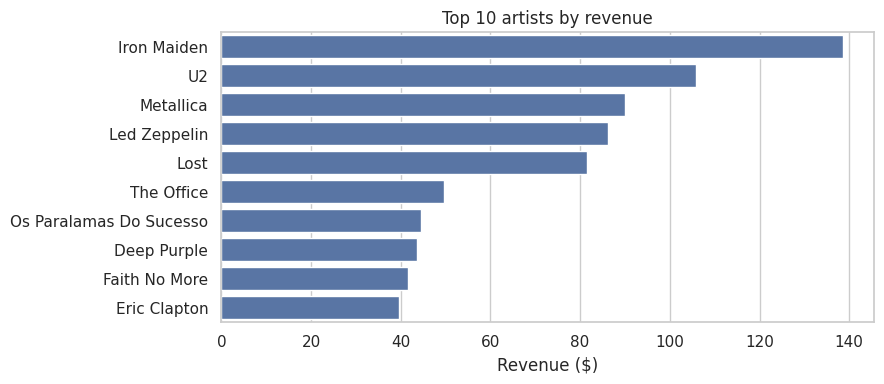

In [3]:
q2 = """
SELECT ar.Name AS artist,
       SUM(il.Quantity) AS units_sold,
       ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM InvoiceLine il
JOIN Track  t  ON t.TrackId  = il.TrackId
JOIN Album  al ON al.AlbumId = t.AlbumId
JOIN Artist ar ON ar.ArtistId = al.ArtistId
GROUP BY ar.ArtistId, ar.Name
ORDER BY revenue DESC
LIMIT 10
"""
q2_df = run(q2)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=q2_df, x="revenue", y="artist", color="#4C72B0", ax=ax)
ax.set_title("Top 10 artists by revenue"); ax.set_xlabel("Revenue ($)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

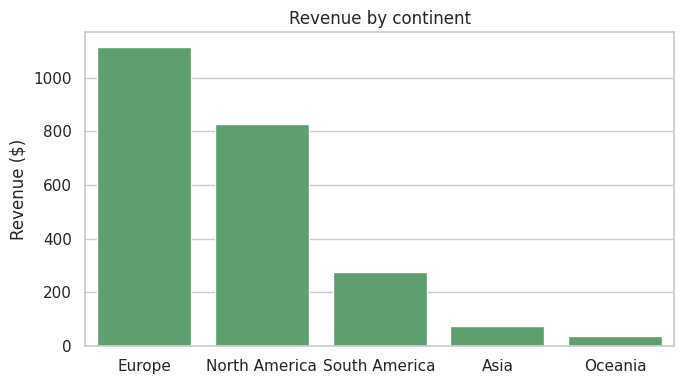

In [4]:
q3 = """
SELECT
    CASE
        WHEN BillingCountry IN ('USA', 'Canada')                THEN 'North America'
        WHEN BillingCountry IN ('Brazil', 'Argentina', 'Chile') THEN 'South America'
        WHEN BillingCountry = 'India'                           THEN 'Asia'
        WHEN BillingCountry = 'Australia'                       THEN 'Oceania'
        ELSE 'Europe'
    END AS region,
    COUNT(*) AS invoices,
    ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY region
ORDER BY revenue DESC
"""
q3_df = run(q3)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=q3_df, x="region", y="revenue", color="#55A868", ax=ax)
ax.set_title("Revenue by continent"); ax.set_ylabel("Revenue ($)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

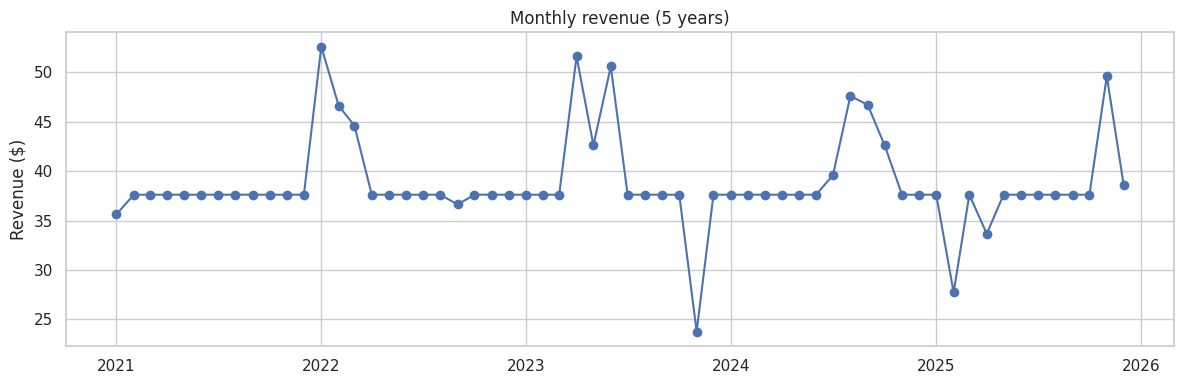

In [5]:
q4 = """
WITH monthly AS (
    SELECT strftime('%Y-%m', InvoiceDate) AS month,
           ROUND(SUM(Total), 2) AS revenue
    FROM Invoice GROUP BY 1
)
SELECT month, revenue,
       ROUND(revenue - LAG(revenue) OVER (ORDER BY month), 2) AS mom_change,
       ROUND(SUM(revenue) OVER (ORDER BY month), 2)           AS running_total
FROM monthly ORDER BY month
"""
q4_df = run(q4)

q4_df["month_dt"] = pd.to_datetime(q4_df["month"] + "-01")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(q4_df["month_dt"], q4_df["revenue"], marker="o", lw=1.5)
ax.set_title("Monthly revenue (5 years)"); ax.set_ylabel("Revenue ($)")
plt.tight_layout(); plt.show()

## Key Findings

- **Revenue:** ~$2,329 across 412 invoices; invoice totals match line items exactly (0 mismatches).
- **Top products:** Rock dominates (~36% of revenue); Iron Maiden, U2, Metallica lead artists.
- **Regions:** Europe ~48%, North America ~36%, South America ~12%. USA is the largest single country.
- **Trend:** Flat — ~$39/month, no seasonality, no growth. Growth needs new levers (markets, pricing, promos).
- **Opportunity:** ~43% of tracks have never sold → test bundles/recommendations.

## SQL Concepts Used
| Concept | Where |
|---|---|
| Multi-table JOINs | Q2 (4 tables), Q3, Q4 |
| GROUP BY + aggregations | All |
| CASE WHEN | Q3 |
| Window functions (`LAG`, running `SUM`, `RANK`, `DENSE_RANK`) | Q4, Q5 |
| Date functions (`strftime`) | Q4 |